**Step 1 — Load and inspect the dataset**

In [43]:

import pandas as pd
from sklearn.datasets import load_breast_cancer

# Load the Breast Cancer Wisconsin dataset
cancer_data = load_breast_cancer(as_frame=True)

# Create a DataFrame containing all features and the target
df = cancer_data.frame.copy()

# Inspect the dataset
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["target"].value_counts())

print("\nTarget labels:")
print(dict(enumerate(cancer_data.target_names)))

print("\nFirst five rows:")
print(df.head())


Dataset shape: (569, 31)

Column names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']

Missing values:
0

Duplicate rows: 0

Target distribution:
target
1    357
0    212
Name: count, dtype: int64

Target labels:
{0: np.str_('malignant'), 1: np.str_('benign')}

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77 

**Dataset Validation and Train-Test Split**

It contains 569 records, 30 input features, no missing values or duplicate rows, and 2 target classes.
- 0 – Malignant: 212 records (37.3%)
- 1 – Benign: 357 records (62.7%)
Since the dataset has a slight class imbalance, we use stratified splitting to maintain approximately the same class distribution in both training and testing datasets.

We split the data into:
- 80% Training: 455 records, used to train the classifiers.
- 20% Testing: 114 records, used to evaluate model performance on unseen data.
This ensures a fair and reliable evaluation of the five classifiers.

**Step 2 - 80:20 train/test split.**

In [44]:

from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["target"])
y = df["target"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

# Save the test data for the Streamlit application
test_data = X_test.copy()
test_data["target"] = y_test
test_data.to_csv("test_data.csv", index=False)

print("\ntest_data.csv saved successfully!")


Training features: (455, 30)
Testing features: (114, 30)

Training target distribution:
target
1    0.626374
0    0.373626
Name: proportion, dtype: float64

Testing target distribution:
target
1    0.631579
0    0.368421
Name: proportion, dtype: float64

test_data.csv saved successfully!


**Step 3 — Data Preprocessing**

We use StandardScaler to bring all 30 numerical features to a common scale, with a mean of approximately 0 and standard deviation of 1.

The scaler is fitted only on training data and then applied to both training and testing data to prevent data leakage.

In [45]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (455, 30)
Testing data shape: (114, 30)


**Step 4 — Train the Five Classification Models**

Objective: Train each model to predict whether a tumour is Malignant (0) or Benign (1).
The five classifiers
1. Logistic Regression – Uses a mathematical function to predict the probability of each class.
2. K-Nearest Neighbors (KNN) – Classifies a record based on the classes of its nearest data points.
3. Decision Tree – Makes predictions using a series of decision rules.
4. Random Forest – Combines multiple decision trees to improve prediction reliability.
5. Support Vector Machine (SVM) – Finds an optimal boundary to separate the two classes.

In [46]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(probability=True, random_state=42)
}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully
KNN trained successfully
Naive Bayes trained successfully
SVM trained successfully


**Step 5 – Evaluate the Five Classifiers**

Now we test all five trained models using the 114 testing records that the models have never seen before.
Step 1 – Understand the evaluation metrics
We will calculate four metrics:
- Accuracy: Percentage of total predictions that are correct.
- Precision: Out of all cases predicted as positive (Benign = 1), how many are actually benign?
- Recall: Out of all actual positive cases, how many did the model correctly identify?
- F1-score: Balance between precision and recall.

In [47]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

results = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1] # Probability of Class 1

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred, pos_label=0),
        "Recall": recall_score(y_test, y_pred, pos_label=0),
        "F1 Score": f1_score(y_test, y_pred, pos_label=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy     AUC  Precision  Recall  F1 Score     MCC
0  Logistic Regression    0.9825  0.9954     0.9762  0.9762    0.9762  0.9623
1        Decision Tree    0.9123  0.9157     0.8478  0.9286    0.8864  0.8174
2                  KNN    0.9561  0.9788     0.9512  0.9286    0.9398  0.9054
3          Naive Bayes    0.9298  0.9868     0.9048  0.9048    0.9048  0.8492
4                  SVM    0.9825  0.9950     0.9762  0.9762    0.9762  0.9623


**Observations:**

- Logistic Regression achieved the highest AUC (0.9954) and tied with SVM for the highest accuracy (98.25%).
- SVM delivered nearly identical performance to Logistic Regression across all six metrics.
- KNN showed good overall performance, achieving 95.61% accuracy.
- Naive Bayes achieved a high AUC of 0.9868 but comparatively lower accuracy.
- Decision Tree recorded the lowest accuracy (91.23%) and AUC (0.9157).

**Conclusion:**

Logistic Regression emerged as the best-performing classifier on the test dataset, closely followed by SVM. Both achieved 98.25% accuracy and an MCC score of 0.9623, demonstrating strong classification performance. Logistic Regression had a marginal advantage in AUC.

**Step 6 – Confusion Matrix and Classification Report**

In [48]:
from sklearn.metrics import confusion_matrix, classification_report

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)

    print("\n", name)
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred,
        target_names=["Malignant", "Benign"]
    ))


 Logistic Regression
Confusion Matrix:
[[41  1]
 [ 1 71]]

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


 Decision Tree
Confusion Matrix:
[[39  3]
 [ 7 65]]

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.85      0.93      0.89        42
      Benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114


 KNN
Confusion Matrix:
[[39  3]
 [ 2 70]]

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Beni

The confusion matrices and classification reports were evaluated for five machine learning algorithms: Logistic Regression, Decision Tree, K-Nearest Neighbors (KNN), Naive Bayes, and Support Vector Machine (SVM).

Logistic Regression and SVM achieved the highest accuracy of 98.25%, with an F1-score of 0.98 for the malignant class. Both models correctly classified 41 out of 42 malignant cases and 71 out of 72 benign cases.

KNN achieved an accuracy of 95.61%, followed by Naive Bayes at 92.98% and Decision Tree at 91.23%.

From the perspective of malignant case detection, Logistic Regression and SVM performed better, with only one malignant case incorrectly classified as benign.

Overall, Logistic Regression and SVM demonstrated the strongest classification performance among the five models on the given test dataset.

**Model Performance Comparison chart**


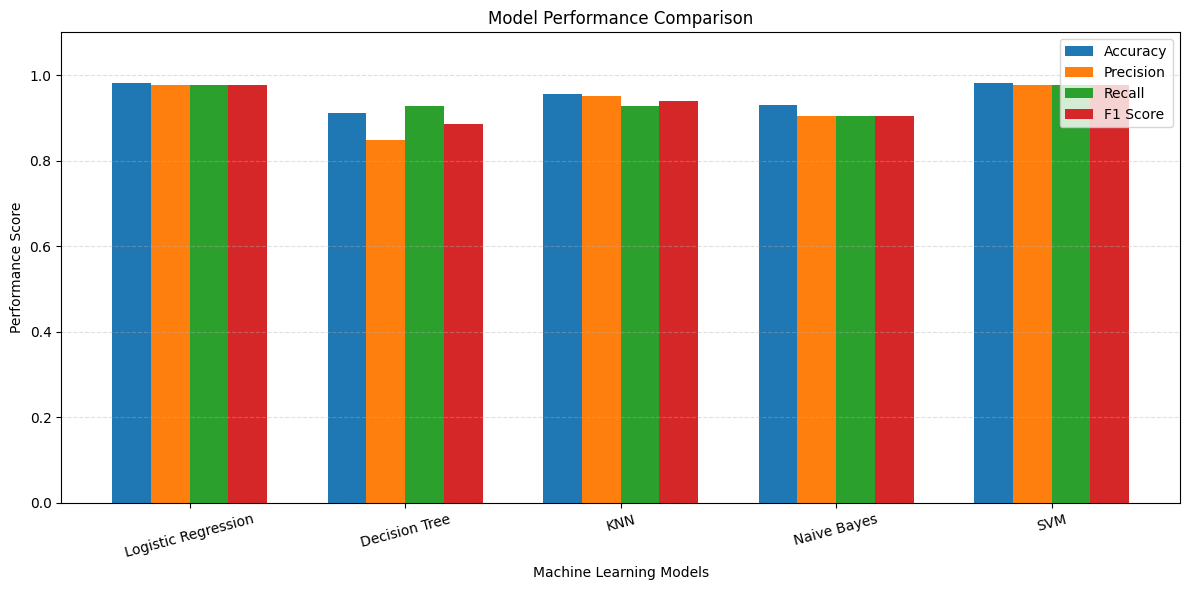

In [49]:

import matplotlib.pyplot as plt
import numpy as np

# Select performance metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

# Prepare data
x = np.arange(len(results_df['Model']))
width = 0.18

# Create figure
plt.figure(figsize=(12, 6))

# Plot each metric
for i, metric in enumerate(metrics):
    plt.bar(
        x + (i - 1.5) * width,
        results_df[metric],
        width,
        label=metric
    )

# Add labels and title
plt.xlabel('Machine Learning Models')
plt.ylabel('Performance Score')
plt.title('Model Performance Comparison')

plt.xticks(x, results_df['Model'], rotation=15)
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


**ROC Curve Comparison**

Logistic Regression: AUC = 0.9954
Decision Tree: AUC = 0.9157
KNN: AUC = 0.9788
Naive Bayes: AUC = 0.9868
SVM: AUC = 0.9950


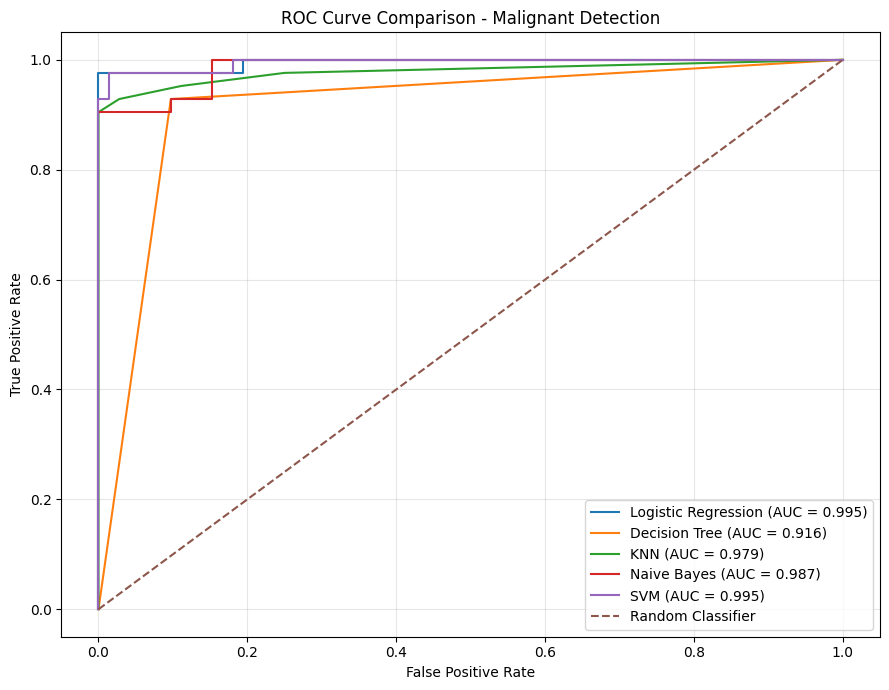

In [50]:


from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

for name, model in models.items():

    # Get prediction scores for Malignant (class 0)
    if hasattr(model, "predict_proba"):
        malignant_index = list(model.classes_).index(0)
        y_scores = model.predict_proba(X_test_scaled)[:, malignant_index]

    else:
        y_scores = model.decision_function(X_test_scaled)

        # Reverse scores if class 0 is the first class
        if model.classes_[0] == 0:
            y_scores = -y_scores

    # Calculate ROC values
    fpr, tpr, thresholds = roc_curve(
        y_test, y_scores, pos_label=0
    )

    # Calculate AUC
    roc_auc = auc(fpr, tpr)
    print(f"{name}: AUC = {roc_auc:.4f}")

    # Plot ROC curve
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})')

# Random classifier reference
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison - Malignant Detection')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Five machine learning classification algorithms were evaluated: Logistic Regression, Decision Tree, K-Nearest Neighbors (KNN), Naive Bayes, and Support Vector Machine (SVM).

The models were compared using accuracy, precision, recall, F1-score, confusion matrices, and ROC-AUC.

Logistic Regression achieved the highest accuracy of 98.25% and an ROC-AUC score of 0.9954. SVM also achieved 98.25% accuracy with an ROC-AUC of 0.9950.

Logistic Regression demonstrated strong performance in identifying malignant cases, achieving a recall of 98% and an F1-score of 0.98. It incorrectly classified only one malignant case as benign.

Based on the overall evaluation metrics, Logistic Regression was selected as the best-performing model among the five algorithms. SVM was a close competitor.

These results indicate strong classification performance on the given test dataset.

In [51]:
print(models.keys())

dict_keys(['Logistic Regression', 'Decision Tree', 'KNN', 'Naive Bayes', 'SVM'])


**Save the selected model**

In [52]:
import joblib
from sklearn.pipeline import Pipeline

# Combine the fitted scaler and trained Logistic Regression model
best_model = Pipeline([
    ('scaler', scaler),
    ('classifier', models['Logistic Regression'])
])

# Save the pipeline
joblib.dump(best_model, 'best_breast_cancer_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [53]:
loaded_model = joblib.load('best_breast_cancer_model.pkl')

print("Model loaded successfully!")

Model loaded successfully!


In [54]:
import numpy as np

# Predict using the loaded pipeline
loaded_predictions = loaded_model.predict(X_test)

# Predict using the original trained model
original_predictions = models['Logistic Regression'].predict(X_test_scaled)

# Compare predictions
if np.array_equal(loaded_predictions, original_predictions):
    print("SUCCESS: Both predictions are identical!")
else:
    print("Predictions do not match.")

SUCCESS: Both predictions are identical!


In [55]:
# Select one sample from test dataset
sample = X_test.iloc[[0]]

# Predict using the saved model
prediction = loaded_model.predict(sample)[0]

# Display result
if prediction == 0:
    print("Predicted Class: Malignant")
else:
    print("Predicted Class: Benign")

print("Actual Class:", y_test.iloc[0])

Predicted Class: Malignant
Actual Class: 0


In [56]:
import pandas as pd

# Prepare test dataset using original feature names
test_data = pd.DataFrame(
    X_test,
    columns=X.columns
)

# Add actual target labels
test_data["target"] = y_test

# Save as CSV
test_data.to_csv("test_data.csv", index=False)

print("Test dataset saved successfully!")
print("Shape:", test_data.shape)

test_data.head()

Test dataset saved successfully!
Shape: (114, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
256,19.55,28.77,133.60,1207.0,0.09260,0.20630,0.17840,0.11440,0.1893,0.06232,...,36.27,178.60,1926.0,0.1281,0.53290,0.4251,0.19410,0.2818,0.10050,0
428,11.13,16.62,70.47,381.1,0.08151,0.03834,0.01369,0.01370,0.1511,0.06148,...,20.29,74.35,421.1,0.1030,0.06219,0.0458,0.04044,0.2383,0.07083,1
501,13.82,24.49,92.33,595.9,0.11620,0.16810,0.13570,0.06759,0.2275,0.07237,...,32.94,106.00,788.0,0.1794,0.39660,0.3381,0.15210,0.3651,0.11830,0
363,16.50,18.29,106.60,838.1,0.09686,0.08468,0.05862,0.04835,0.1495,0.05593,...,25.45,117.20,1009.0,0.1338,0.16790,0.1663,0.09123,0.2394,0.06469,1
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.1410,0.21130,0.4107,0.22160,0.2060,0.07115,0


In [57]:
from google.colab import files

files.download("test_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [58]:
import joblib
import os

# Create models directory
os.makedirs("models", exist_ok=True)

# Get the best-performing model
best_model = models["Logistic Regression"]

# Save trained model
joblib.dump(best_model, "models/logistic_regression_model.pkl")

# Save the fitted scaler
joblib.dump(scaler, "models/scaler.pkl")

print("Models saved successfully!")
print("1. logistic_regression_model.pkl")
print("2. scaler.pkl")

Models saved successfully!
1. logistic_regression_model.pkl
2. scaler.pkl


In [59]:
print(os.listdir("models"))

['scaler.pkl', 'logistic_regression_model.pkl']


In [60]:
from google.colab import files

files.download("models/logistic_regression_model.pkl")
# files.download("models/scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [61]:
!pip install streamlit

In [62]:
import sklearn
import streamlit
import pandas
import joblib

print("Scikit-learn:", sklearn.__version__)
print("Streamlit:", streamlit.__version__)
print("Pandas:", pandas.__version__)
print("Joblib:", joblib.__version__)

Scikit-learn: 1.6.1
Streamlit: 1.67.0
Pandas: 2.2.3
Joblib: 1.6.0


In [63]:
import joblib
from sklearn.metrics import accuracy_score, confusion_matrix

# Load the saved model and scaler
loaded_model = joblib.load("logistic_regression_model.pkl")
loaded_scaler = joblib.load("scaler.pkl")

# Transform test data
X_test_scaled = loaded_scaler.transform(X_test)

# Generate predictions using saved model
saved_predictions = loaded_model.predict(X_test_scaled)

# Compare with original model predictions
original_predictions = models["Logistic Regression"].predict(X_test_scaled)

print("Saved model verification:")
print("Predictions identical:",
      (saved_predictions == original_predictions).all())

print("Accuracy:", accuracy_score(y_test, saved_predictions))

print("Confusion Matrix:")
print(confusion_matrix(y_test, saved_predictions))

Saved model verification:
Predictions identical: True
Accuracy: 0.9824561403508771
Confusion Matrix:
[[41  1]
 [ 1 71]]


In [64]:
import joblib

loaded_model = joblib.load(
    "logistic_regression_model.pkl"
)

loaded_scaler = joblib.load(
    "scaler.pkl"
)

print("Model and scaler loaded successfully!")

Model and scaler loaded successfully!


In [65]:
import os

os.makedirs("Results", exist_ok=True)

print("Results folder created successfully!")

Results folder created successfully!


In [66]:
results_df.to_csv(
    "Results/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [67]:
import pandas as pd

comparison = pd.read_csv("Results/model_comparison.csv")
display(comparison)

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.982456,0.995370,0.976190,0.976190,0.976190,0.962302
1,Decision Tree,0.912281,0.915675,0.847826,0.928571,0.886364,0.817412
2,KNN,0.956140,0.978836,0.951220,0.928571,0.939759,0.905447
3,Naive Bayes,0.929825,0.986772,0.904762,0.904762,0.904762,0.849206
4,SVM,0.982456,0.995040,0.976190,0.976190,0.976190,0.962302


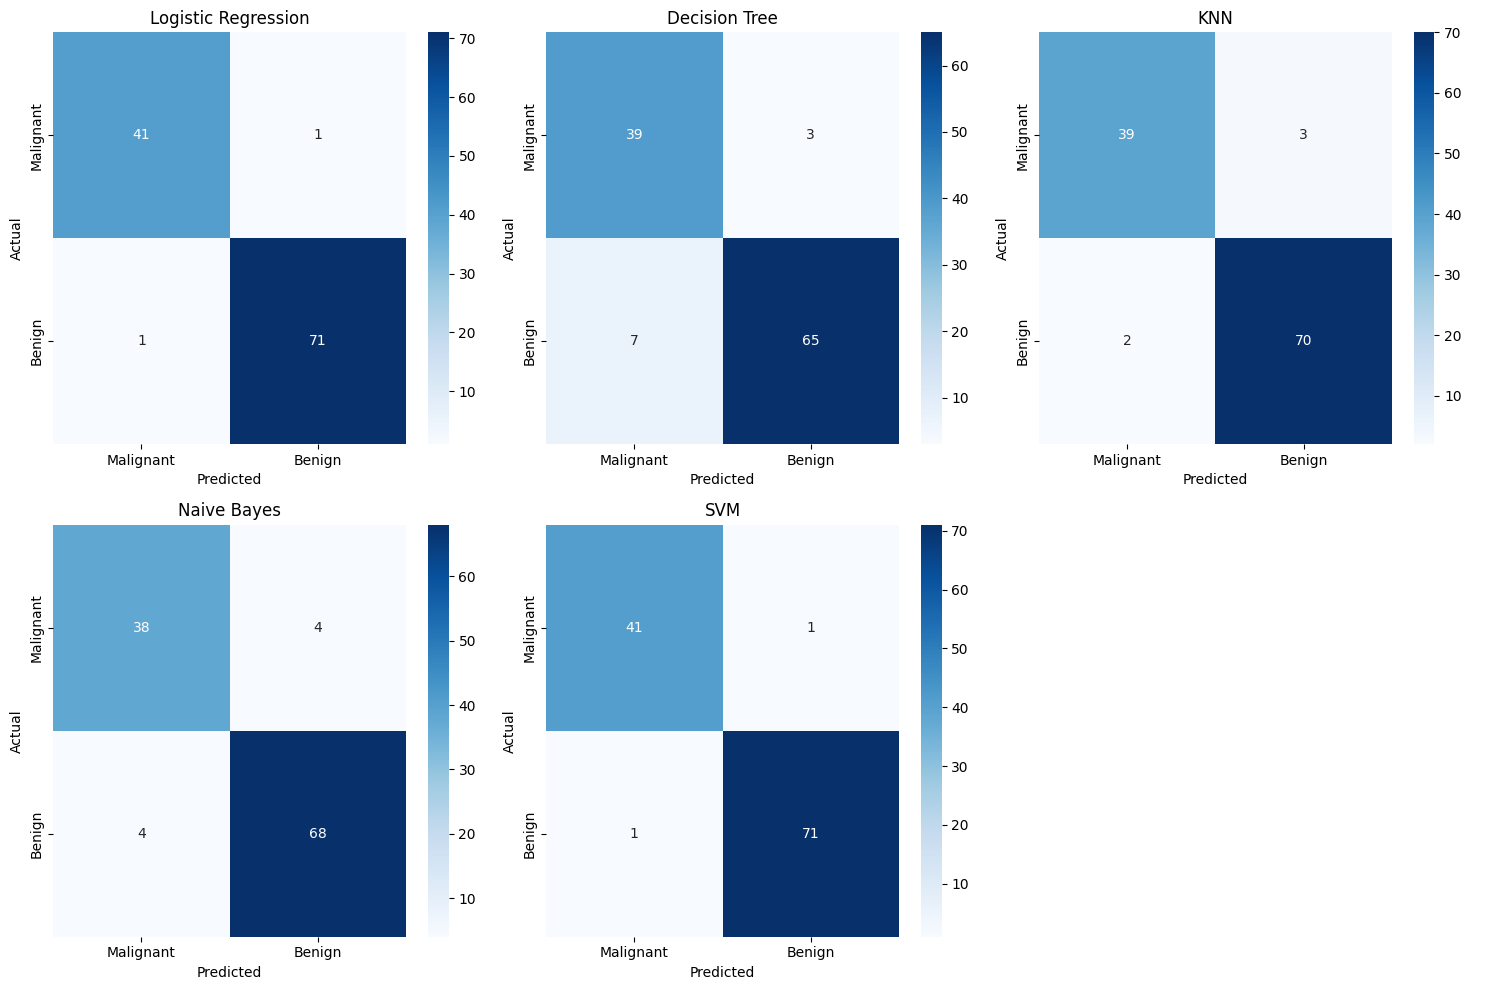

Confusion matrices saved successfully!


In [68]:


import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test_scaled)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Malignant", "Benign"],
        yticklabels=["Malignant", "Benign"],
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

axes[-1].axis("off")

plt.tight_layout()
plt.savefig("Results/confusion_matrices.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrices saved successfully!")


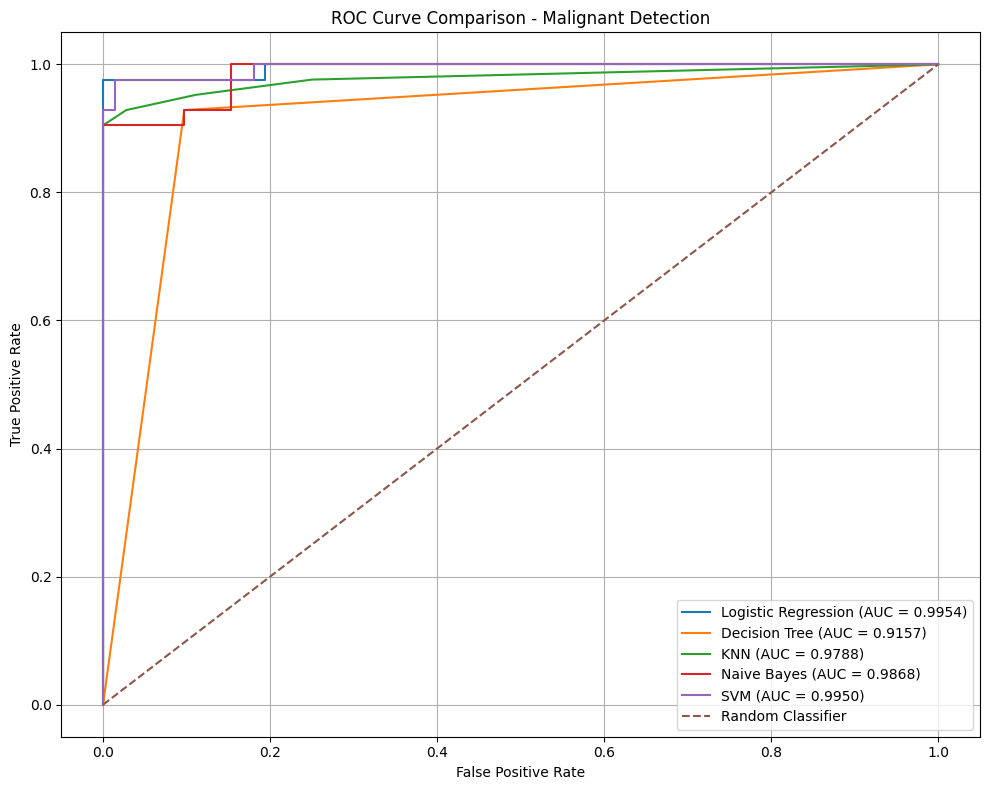

ROC curves saved successfully!


In [69]:


from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for name, model in models.items():

    y_prob = model.predict_proba(X_test_scaled)[:, 0]
    y_test_roc = (y_test == 0).astype(int)

    fpr, tpr, thresholds = roc_curve(y_test_roc, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Malignant Detection")
plt.legend(loc="lower right")
plt.grid()

plt.tight_layout()
plt.savefig("Results/roc_curves.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("ROC curves saved successfully!")
